# Harassment and Bullying in U.S. Public Schools
## A reproducible analysis of the 2015–16 Civil Rights Data Collection

**Research question:** How did reported harassment and bullying vary by basis, and how did the sex composition of reported students differ across categories?

This notebook contains the analysis code, explanations, validation results, tables and three visualizations. It runs independently of `analysis.py` and preserves all original Excel workbooks.

**Scope:** descriptive analysis of historical administrative reports. Allegations, students reported as harassed or bullied, and students disciplined are different measures. They cannot be combined into a case-resolution rate.

## 1. Data source, permission and setup

**Producer:** U.S. Department of Education, Office for Civil Rights (OCR), Civil Rights Data Collection (CRDC), school year **2015–16**.

**Source and downloads:** [Official dataset catalog](https://catalog.data.gov/dataset/2015-16-harassment-or-bullying-by-basis-category-civil-rights-data-collection). The catalog identifies public access and a **CC BY** license. Retain this attribution when sharing the source data or derived figures. Only aggregate state and national records are used.

Keep this notebook beside the `dataset/` directory containing the seven supplied Excel files. Use Python 3.11 or 3.12. Install the notebook environment in a terminal with:

```bash
python -m pip install -r requirements-notebook.txt
python -m jupyterlab
```

Open `analysis.ipynb`, select that Python environment, then choose **Restart Kernel and Run All Cells** (or your editor's equivalent). Run cells in order. Figures and tables are saved under `results/`, and figures are also embedded below for GitHub viewing. No internet access is required during the analysis after dependencies and input files are available.

## 2. Import libraries and configure paths

The notebook uses paths relative to its working directory rather than `__file__`, which is unavailable in Jupyter. Start Jupyter from the project directory. A parent-directory fallback supports editors that start the kernel one folder below the project.

In [1]:
from __future__ import annotations
import hashlib
import importlib.metadata
import json
import platform
import warnings
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import display, Image, Markdown

In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").is_dir() and (ROOT.parent / "dataset").is_dir():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "dataset"
OUTPUT_DIR = ROOT / "results"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Cannot find dataset/. Start Jupyter in the directory containing "
        "analysis.ipynb, or set ROOT to that project directory in this cell."
    )
print(f"Input workbooks found: {len(list(DATA_DIR.glob('*.xlsx')))}")
print("Generated files will be saved in results/.")

Input workbooks found: 7
Generated files will be saved in results/.


In [3]:
SOURCE_URL = 'https://catalog.data.gov/dataset/2015-16-harassment-or-bullying-by-basis-category-civil-rights-data-collection'

BASES = ('sex', 'race', 'disability')

BASIS_LABELS = {'sex': 'Sex', 'race': 'Race, color, or national origin', 'disability': 'Disability', 'sexual_orientation': 'Sexual orientation', 'religion': 'Religion'}

REGIONS = set('Alabama|Alaska|Arizona|Arkansas|California|Colorado|Connecticut|Delaware|District of Columbia|Florida|Georgia|Hawaii|Idaho|Illinois|Indiana|Iowa|Kansas|Kentucky|Louisiana|Maine|Maryland|Massachusetts|Michigan|Minnesota|Mississippi|Missouri|Montana|Nebraska|Nevada|New Hampshire|New Jersey|New Mexico|New York|North Carolina|North Dakota|Ohio|Oklahoma|Oregon|Pennsylvania|Rhode Island|South Carolina|South Dakota|Tennessee|Texas|Utah|Vermont|Virginia|Washington|West Virginia|Wisconsin|Wyoming'.split('|'))

## 3. Read and clean the Excel tables

Each relevant sheet has a United States total, 50 states and the District of Columbia. Row selection uses the geography column, avoiding decorative headings, footnotes and stray scratch values. Unrelated/repeated labels in column A are ignored; file names and B2 table titles determine the student measure and basis. The malformed race-related allegation heading is normalized to “Race, color, or national origin.”

Extracted fields include the relevant counts, source sex categories, number of schools and school-reporting coverage. Detailed race/ethnicity, IDEA, Section 504 and English-learner breakdowns are outside this analysis. Missing or invalid counts cause an error rather than becoming zero. Reporting coverage below 85% is flagged; it is not a bullying prevalence rate.

In [4]:
def require(condition: bool, message: str) -> None:
    """Do not continue with misleading results if an input assumption fails."""
    if not condition:
        raise ValueError(message)

def count(value: object, context: str) -> int:
    """Require a nonnegative integer; blanks/suppression codes are not zero."""
    try:
        numeric = float(str(value).replace(',', ''))
    except (TypeError, ValueError) as exc:
        raise ValueError(f'Missing or nonnumeric count at {context}: {value!r}') from exc
    require(np.isfinite(numeric) and numeric >= 0 and numeric.is_integer(), f'Invalid count at {context}: {value!r}')
    return int(numeric)

def coverage(value: object, context: str) -> float:
    try:
        result = float(value)
    except (TypeError, ValueError) as exc:
        raise ValueError(f'Missing reporting coverage at {context}') from exc
    require(np.isfinite(result) and 0 <= result <= 100, f'Coverage must be between 0 and 100 at {context}')
    return result

In [5]:
def read_inputs(dataset_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, list[dict]]:
    """Flatten relevant columns from 19 sheets into two tidy data tables."""
    student_records, allegation_records, audit = ([], [], [])
    specifications = [('Allegations-of-Harassment-or-Bullying.xlsx', None, 'allegations')]
    specifications += [(f'Harassment-Bullying-on-basis-of-{basis}-{measure}.xlsx', basis, measure) for basis in BASES for measure in ('reported', 'disciplined')]
    for filename, basis, measure in specifications:
        path = dataset_dir / filename
        if not path.is_file():
            raise FileNotFoundError(f'Required workbook is missing: {path}')
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', message='Unknown extension is not supported')
            workbook = openpyxl.load_workbook(path, read_only=True, data_only=True)
            try:
                sheets = ('Total',) if basis is None else ('Total', 'Male', 'Female')
                require(set(sheets).issubset(workbook.sheetnames), f'Unexpected sheets in {filename}')
                for sheet_name in sheets:
                    rows = list(workbook[sheet_name].values)
                    title = str(rows[1][1])
                    require('2015-16' in title and 'harass' in title.lower() and ('bull' in title.lower()), f'Unexpected table title: {filename}/{sheet_name}')
                    if basis is not None:
                        require(f'basis of {basis}' in title.lower(), f'Basis mismatch in {filename}')
                        title_word = 'disciplined' if measure == 'disciplined' else 'reported'
                        require(title_word in title.lower(), f'Measure mismatch in {filename}')
                    require(str(rows[3][1]).strip() == 'State', f'State header missing in {filename}')
                    expected_header = 'Total number of allegations' if basis is None else 'Total Students'
                    require(str(rows[3][2]).strip() == expected_header, f'Count header changed in {filename}')
                    data_rows = [(i, row) for i, row in enumerate(rows, 1) if len(row) > 1 and row[1] in REGIONS | {'United States'}]
                    names = [row[1] for _, row in data_rows]
                    require(len(names) == 52 and set(names) == REGIONS | {'United States'}, f'Expected 50 states, DC and US exactly once: {filename}/{sheet_name}')
                    coverage_index = 9 if basis is None else 24
                    school_index = 8 if basis is None else 23
                    for row_number, row in data_rows:
                        context = f'{filename}/{sheet_name}/row {row_number}'
                        common = {'school_year': '2015-16', 'state': row[1], 'is_national': row[1] == 'United States', 'number_of_schools': count(row[school_index], context), 'reporting_coverage_pct': coverage(row[coverage_index], context), 'source_file': filename, 'source_sheet': sheet_name, 'source_row': row_number}
                        common['coverage_below_85_pct'] = common['reporting_coverage_pct'] < 85
                        if basis is None:
                            record = {**common, 'total_allegations': count(row[2], context)}
                            for col, category in enumerate(('sex', 'race', 'disability', 'sexual_orientation', 'religion'), 3):
                                record[category] = count(row[col], context)
                            require(sum((record[k] for k in BASIS_LABELS)) == record['total_allegations'], f'Allegation categories do not reconcile: {context}')
                            allegation_records.append(record)
                        else:
                            student_records.append({**common, 'basis': basis, 'measure': measure, 'sex': sheet_name, 'student_count': count(row[2], context)})
                    audit.append({'file': filename, 'sheet': sheet_name, 'title': title, 'geography_rows': len(data_rows), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()})
            finally:
                workbook.close()
    return (pd.DataFrame(student_records), pd.DataFrame(allegation_records), audit)

In [6]:
students, allegations, audit = read_inputs(DATA_DIR)
inventory = pd.DataFrame(audit)[["file", "sheet", "geography_rows"]]
display(inventory)
display(pd.DataFrame({
    "table": ["Student counts", "Allegations"],
    "rows": [len(students), len(allegations)],
    "columns": [len(students.columns), len(allegations.columns)],
}))
display(students.head())
display(allegations.head())

,file,sheet,geography_rows
0,Allegations-of-Harassment-or-Bullying.xlsx,Total,52
1,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,52
2,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Male,52
3,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Female,52
4,Harassment-Bullying-on-basis-of-sex-discipline...,Total,52
5,Harassment-Bullying-on-basis-of-sex-discipline...,Male,52
6,Harassment-Bullying-on-basis-of-sex-discipline...,Female,52
7,Harassment-Bullying-on-basis-of-race-reported....,Total,52
8,Harassment-Bullying-on-basis-of-race-reported....,Male,52
9,Harassment-Bullying-on-basis-of-race-reported....,Female,52


,table,rows,columns
0,Student counts,936,13
1,Allegations,52,15


,school_year,state,is_national,number_of_schools,reporting_coverage_pct,source_file,source_sheet,source_row,coverage_below_85_pct,basis,measure,sex,student_count
0,2015-16,United States,True,96360,99.500,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,7,False,sex,reported,Total,43705
1,2015-16,Alabama,False,1400,100.000,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,8,False,sex,reported,Total,581
2,2015-16,Alaska,False,503,100.000,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,9,False,sex,reported,Total,38
3,2015-16,Arizona,False,1977,99.697,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,10,False,sex,reported,Total,957
4,2015-16,Arkansas,False,1092,99.908,Harassment-Bullying-on-basis-of-sex-reported.xlsx,Total,11,False,sex,reported,Total,573


,school_year,state,is_national,number_of_schools,reporting_coverage_pct,source_file,source_sheet,source_row,coverage_below_85_pct,total_allegations,sex,race,disability,sexual_orientation,religion
0,2015-16,United States,True,96360,99.50083,Allegations-of-Harassment-or-Bullying.xlsx,Total,7,False,135192,55579,30913,15345,22143,11212
1,2015-16,Alabama,False,1400,100.00000,Allegations-of-Harassment-or-Bullying.xlsx,Total,8,False,1434,610,516,89,204,15
2,2015-16,Alaska,False,503,100.00000,Allegations-of-Harassment-or-Bullying.xlsx,Total,9,False,58,26,17,4,11,0
3,2015-16,Arizona,False,1977,99.69651,Allegations-of-Harassment-or-Bullying.xlsx,Total,10,False,2780,1553,485,216,423,103
4,2015-16,Arkansas,False,1092,99.81685,Allegations-of-Harassment-or-Bullying.xlsx,Total,11,False,1222,598,405,102,108,9


## 4. Validate internal consistency

Checks cover nonnegative integer counts, valid coverage percentages, exactly 52 geographies per sheet, national/state reconciliation, `Male + Female = Total`, and agreement between allegation categories and the total. **National rows are kept separate, never added to the state rows.** These checks establish internal consistency, not the accuracy of original school reports.

In [7]:
def validate(students: pd.DataFrame, allegations: pd.DataFrame) -> dict:
    """Reconcile national totals and sex subtotals without double counting."""
    for keys, group in students.groupby(['basis', 'measure', 'sex']):
        national = int(group.loc[group.is_national, 'student_count'].iloc[0])
        require(national == int(group.loc[~group.is_national, 'student_count'].sum()), f'National/state reconciliation failed: {keys}')
    for (basis, measure, state), group in students.groupby(['basis', 'measure', 'state']):
        by_sex = group.set_index('sex').student_count
        require(int(by_sex['Total']) == int(by_sex['Male'] + by_sex['Female']), f'Male + Female does not equal Total: {basis}/{measure}/{state}')
    for column in ['total_allegations', *BASIS_LABELS]:
        require(int(allegations.loc[allegations.is_national, column].iloc[0]) == int(allegations.loc[~allegations.is_national, column].sum()), f'Allegation national/state reconciliation failed: {column}')
    return {'status': 'passed', 'workbooks': 7, 'sheets': 19, 'student_table_rows': len(students), 'allegation_table_rows': len(allegations), 'checks': ['52 unique geographies per sheet', 'nonnegative integer counts', 'coverage within 0-100', 'national equals sum of 50 states and DC', 'Male + Female equals Total', 'allegation categories sum to total']}

In [8]:
validation = validate(students, allegations)
display(pd.Series({k: v for k, v in validation.items() if k != "checks"}, name="Validation"))
display(pd.DataFrame({"passed_check": validation["checks"]}))
low_coverage = allegations.loc[
    (~allegations.is_national) & allegations.coverage_below_85_pct,
    ["state", "reporting_coverage_pct", "total_allegations"],
]
display(low_coverage)

status                   passed
workbooks                     7
sheets                       19
student_table_rows          936
allegation_table_rows        52
Name: Validation, dtype: object

,passed_check
0,52 unique geographies per sheet
1,nonnegative integer counts
2,coverage within 0-100
3,national equals sum of 50 states and DC
4,Male + Female equals Total
5,allegation categories sum to total


,state,reporting_coverage_pct,total_allegations
9,District of Columbia,48.868778,116


## 5. Calculate national counts and shares

Allegation shares use total national allegations as the denominator. Sex shares use male plus female **reported students within each basis**. Source sex labels are retained and do not cover all gender identities. Categories may overlap; do not add different bases to estimate unique students.

In [9]:
def style() -> None:
    plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlepad': 20, 'figure.facecolor': '#f8fafc', 'axes.facecolor': '#f8fafc', 'text.color': '#172b42', 'axes.labelcolor': '#172b42', 'savefig.facecolor': '#f8fafc'})

def save_figure(fig: plt.Figure, path: Path, footnote: str) -> None:
    fig.text(0.03, 0.025, footnote, fontsize=9, color='#46566b')
    fig.tight_layout(rect=(0, 0.09, 1, 1))
    fig.savefig(path, dpi=180, bbox_inches='tight', metadata={'Software': 'CISC7204 CRDC analysis'})
    plt.close(fig)

In [10]:
output = OUTPUT_DIR
figures, tables = (output / 'figures', output / 'tables')
figures.mkdir(parents=True, exist_ok=True)
tables.mkdir(parents=True, exist_ok=True)
students.to_csv(tables / 'students_clean.csv', index=False)
allegations.to_csv(tables / 'allegations_clean.csv', index=False)
us = allegations.loc[allegations.is_national].iloc[0]
categories = pd.DataFrame([{'basis': k, 'label': v, 'allegations': int(us[k]), 'share_pct': float(us[k] / us.total_allegations * 100)} for k, v in BASIS_LABELS.items()]).sort_values('allegations', ascending=False)
categories.to_csv(tables / 'national_allegations.csv', index=False)
national = students.loc[students.is_national].copy()
totals = national.loc[national.sex == 'Total'].pivot(index='basis', columns='measure', values='student_count').reindex(BASES)
totals.to_csv(tables / 'national_student_counts.csv')
sex_counts = national.loc[(national.measure == 'reported') & (national.sex != 'Total')].pivot(index='basis', columns='sex', values='student_count').reindex(BASES)
sex_shares = sex_counts.div(sex_counts.sum(axis=1), axis=0) * 100
sex_shares.to_csv(tables / 'reported_sex_shares_pct.csv', float_format='%.6f')
students.loc[~students.is_national & (students.sex == 'Total') & students.coverage_below_85_pct, ['state', 'basis', 'measure', 'reporting_coverage_pct']].to_csv(tables / 'low_coverage_student_tables.csv', index=False)
style()
display(categories)
display(totals)
display(sex_shares.round(2))

,basis,label,allegations,share_pct
0,sex,Sex,55579,41.111160
1,race,"Race, color, or national origin",30913,22.865998
3,sexual_orientation,Sexual orientation,22143,16.378928
2,disability,Disability,15345,11.350524
4,religion,Religion,11212,8.293390


measure,disciplined,reported
basis,,
sex,50191,43705
race,28677,23491
disability,12234,9320


sex,Female,Male
basis,,
sex,63.92,36.08
race,36.55,63.45
disability,33.11,66.89


## 6. Visualization 1 — Allegations by basis

The unit is an allegation, not a unique student. Counts and shares are labeled directly on each bar.

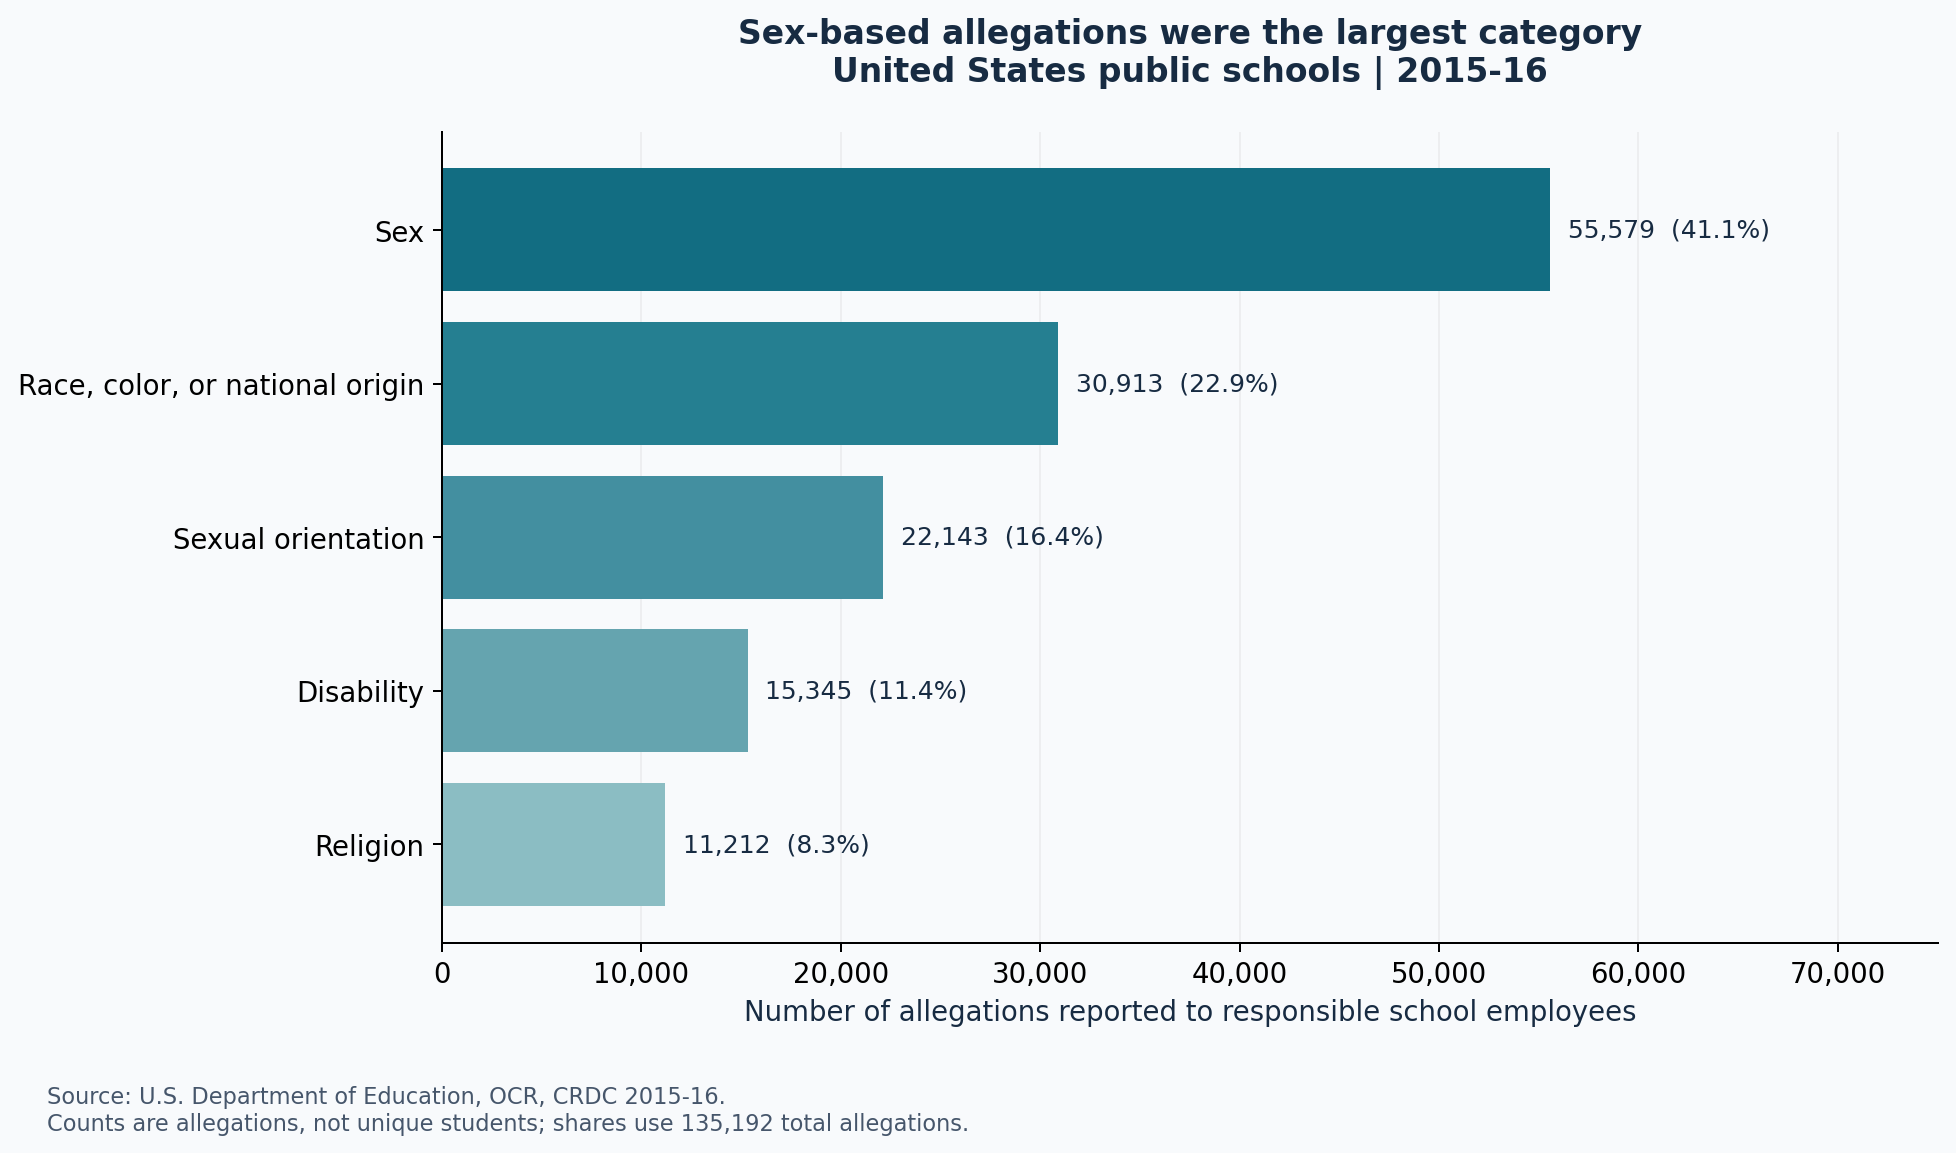

In [11]:
fig, ax = plt.subplots(figsize=(11, 6.5))
bars = ax.barh(categories.label, categories.allegations, color=['#126d82', '#257f91', '#438fa0', '#65a4af', '#8bbdc3'])
ax.invert_yaxis()
ax.bar_label(bars, labels=[f'{r.allegations:,}  ({r.share_pct:.1f}%)' for r in categories.itertuples()], padding=7, fontsize=10)
ax.set_xlim(0, categories.allegations.max() * 1.35)
ax.set_xlabel('Number of allegations reported to responsible school employees')
ax.set_title('Sex-based allegations were the largest category\nUnited States public schools | 2015-16')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.15)
save_figure(fig, figures / '01_allegations_by_basis.png', 'Source: U.S. Department of Education, OCR, CRDC 2015-16.\nCounts are allegations, not unique students; shares use 135,192 total allegations.')
display(Image(filename=str(figures / "01_allegations_by_basis.png")))

In [12]:
display(Markdown(f"**Finding:** Sex-based allegations account for **{int(us.sex):,} of {int(us.total_allegations):,} allegations ({us.sex / us.total_allegations * 100:.1f}%)**, the largest category."))

**Finding:** Sex-based allegations account for **55,579 of 135,192 allegations (41.1%)**, the largest category.

## 7. Visualization 2 — Reported and disciplined student counts

These measures describe different, unlinked groups. Their comparison is descriptive; their ratio is not a discipline success rate. Different reporting coverage can also affect comparisons.

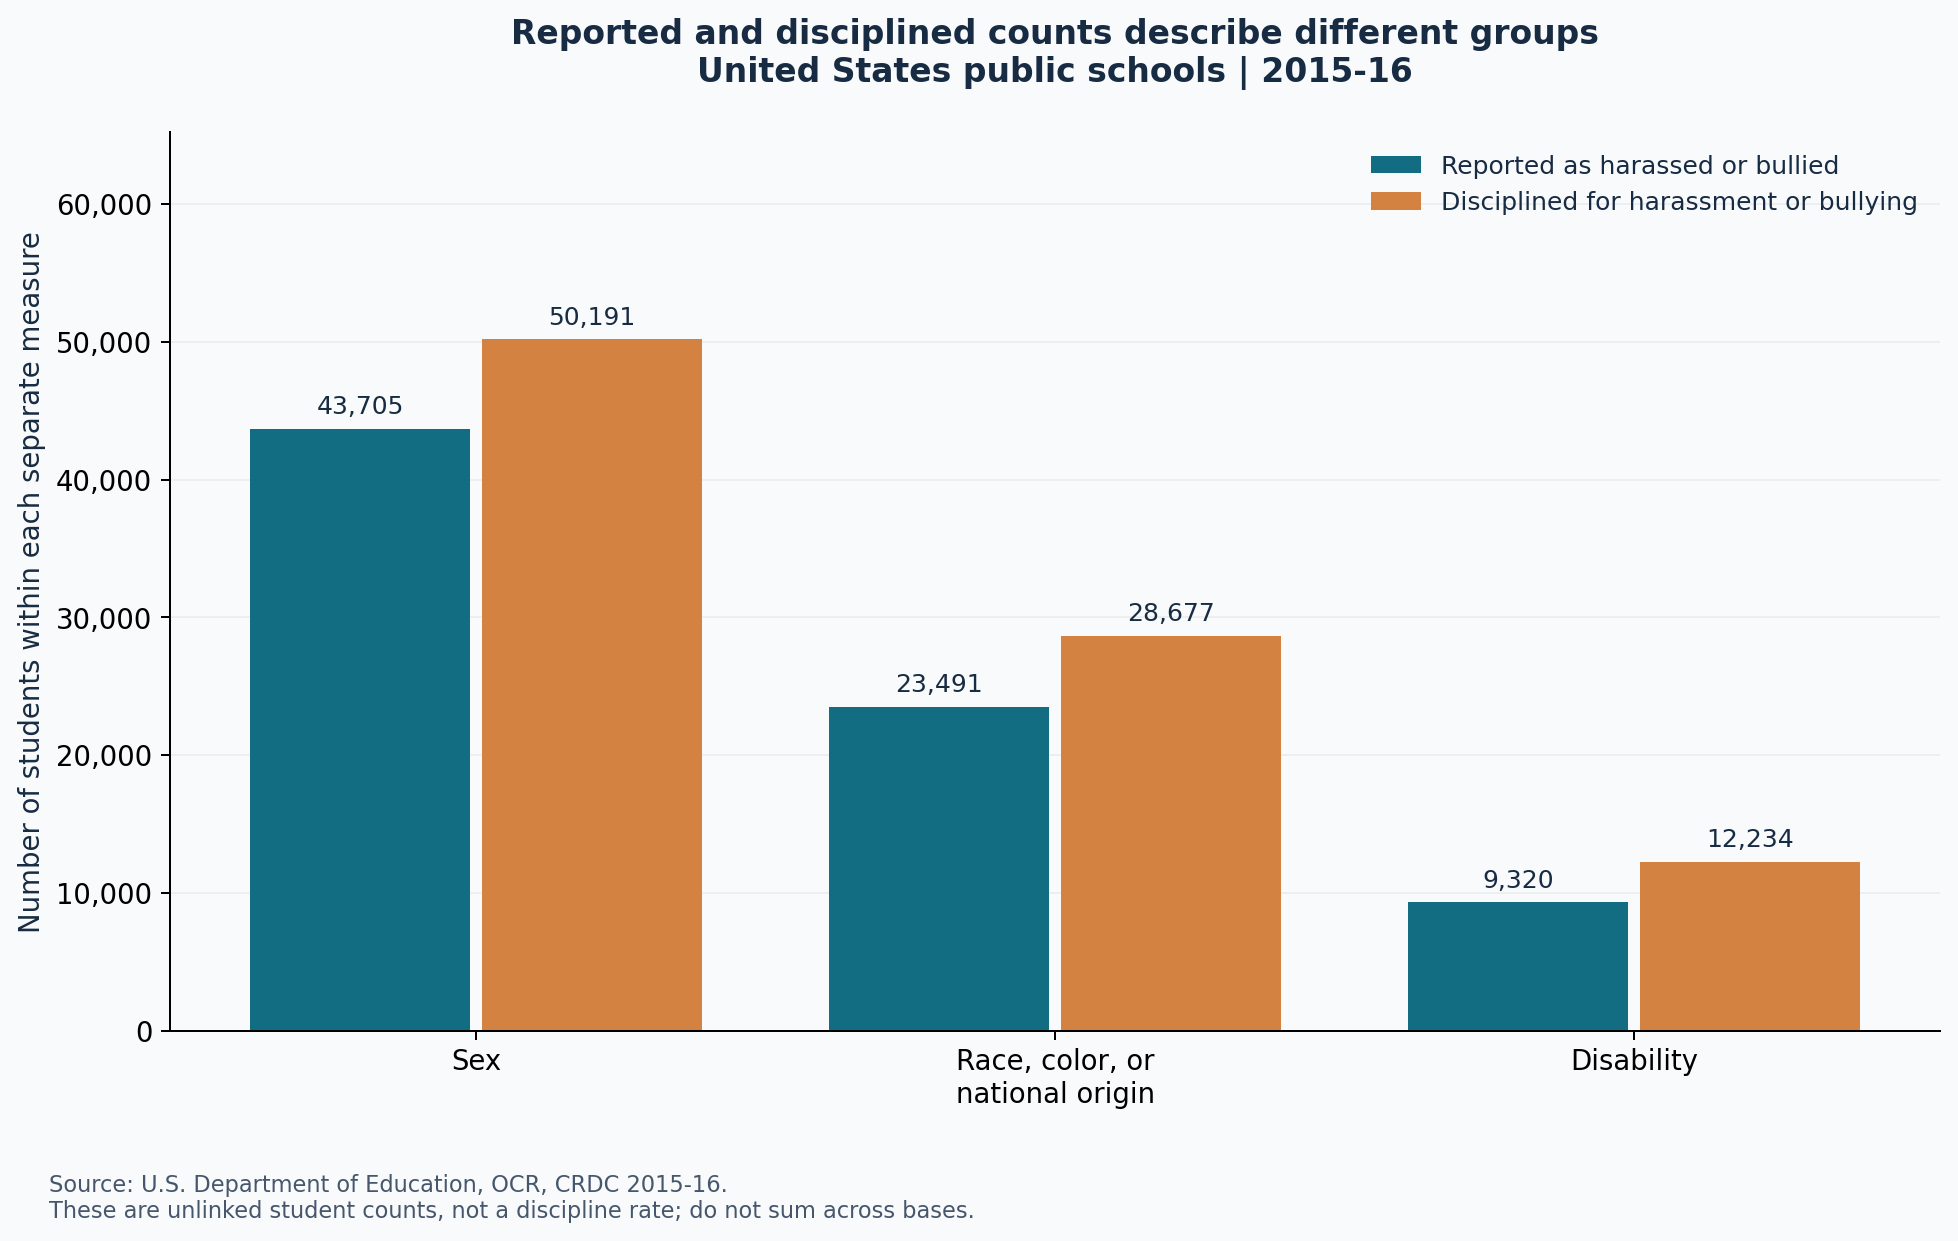

In [13]:
fig, ax = plt.subplots(figsize=(11, 7))
x = np.arange(len(BASES))
first = ax.bar(x - 0.2, totals.reported, 0.38, color='#126d82', label='Reported as harassed or bullied')
second = ax.bar(x + 0.2, totals.disciplined, 0.38, color='#d48242', label='Disciplined for harassment or bullying')
for bars in (first, second):
    ax.bar_label(bars, labels=[f'{v.get_height():,.0f}' for v in bars], padding=4, fontsize=10)
ax.set_xticks(x, ['Sex', 'Race, color, or\nnational origin', 'Disability'])
ax.set_ylim(0, totals.to_numpy().max() * 1.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:,.0f}'))
ax.set_ylabel('Number of students within each separate measure')
ax.set_title('Reported and disciplined counts describe different groups\nUnited States public schools | 2015-16')
ax.legend(frameon=False, fontsize=10)
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.15)
save_figure(fig, figures / '02_reported_and_disciplined.png', 'Source: U.S. Department of Education, OCR, CRDC 2015-16.\nThese are unlinked student counts, not a discipline rate; do not sum across bases.')
display(Image(filename=str(figures / "02_reported_and_disciplined.png")))

In [14]:
display(Markdown(f"**Finding:** The sex-based tables record **{int(totals.loc['sex', 'reported']):,} reported students** and **{int(totals.loc['sex', 'disciplined']):,} disciplined students**. The counts refer to different populations and cannot establish a case-resolution rate."))

**Finding:** The sex-based tables record **43,705 reported students** and **50,191 disciplined students**. The counts refer to different populations and cannot establish a case-resolution rate.

## 8. Visualization 3 — Sex composition among reported students

The denominator is the reported-student count for each basis, not all enrolled students. These are composition shares, not estimates of population risk.

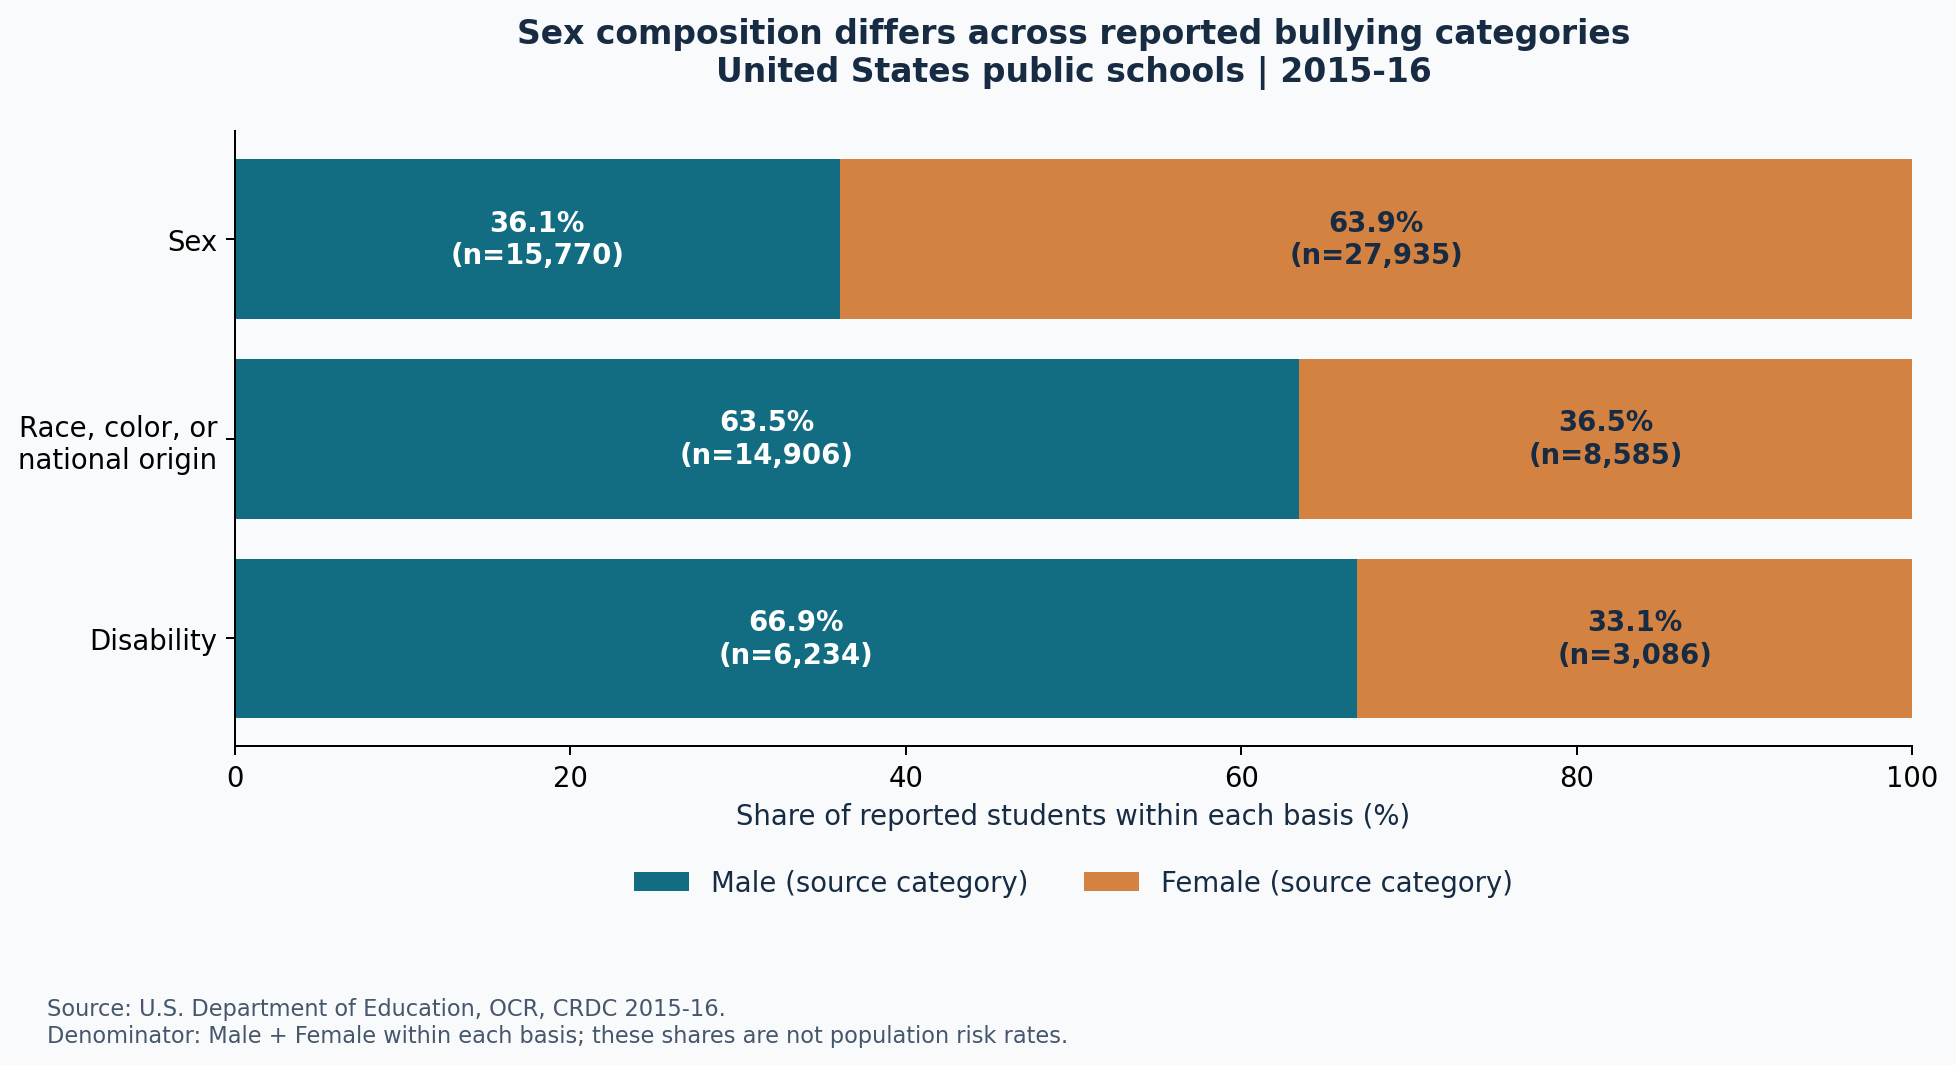

In [15]:
fig, ax = plt.subplots(figsize=(11, 6))
male = sex_shares.Male.to_numpy()
female = sex_shares.Female.to_numpy()
positions = np.arange(3)
ax.barh(positions, male, color='#126d82', label='Male (source category)')
ax.barh(positions, female, left=male, color='#d48242', label='Female (source category)')
for i, basis in enumerate(BASES):
    ax.text(male[i] / 2, i, f"{male[i]:.1f}%\n(n={int(sex_counts.loc[basis, 'Male']):,})", ha='center', va='center', color='white', weight='bold')
    ax.text(male[i] + female[i] / 2, i, f"{female[i]:.1f}%\n(n={int(sex_counts.loc[basis, 'Female']):,})", ha='center', va='center', color='#172b42', weight='bold')
ax.set_yticks(positions, ['Sex', 'Race, color, or\nnational origin', 'Disability'])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Share of reported students within each basis (%)')
ax.set_title('Sex composition differs across reported bullying categories\nUnited States public schools | 2015-16')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
save_figure(fig, figures / '03_reported_students_by_sex.png', 'Source: U.S. Department of Education, OCR, CRDC 2015-16.\nDenominator: Male + Female within each basis; these shares are not population risk rates.')
display(Image(filename=str(figures / "03_reported_students_by_sex.png")))

In [16]:
display(Markdown(f"**Finding:** Female students account for **{sex_shares.loc['sex', 'Female']:.1f}%** of sex-based reported students. Male students account for **{sex_shares.loc['race', 'Male']:.1f}%** of race-based and **{sex_shares.loc['disability', 'Male']:.1f}%** of disability-based reported students."))

**Finding:** Female students account for **63.9%** of sex-based reported students. Male students account for **63.5%** of race-based and **66.9%** of disability-based reported students.

## 9. Export results and record provenance

The following cell saves the findings, validation checks, workbook hashes, software versions and written report. Earlier cells saved the cleaned and summary CSVs and three PNG figures. Rerunning the notebook regenerates those outputs.

In [17]:
findings = {'school_year': '2015-16', 'total_allegations': int(us.total_allegations), 'sex_based_allegations': int(us.sex), 'sex_based_allegations_share_pct': float(us.sex / us.total_allegations * 100), 'female_share_of_sex_based_reported_students_pct': float(sex_shares.loc['sex', 'Female']), 'national_student_counts': {basis: {key: int(totals.loc[basis, key]) for key in ('reported', 'disciplined')} for basis in BASES}, 'national_allegations_school_reporting_coverage_pct': float(us.reporting_coverage_pct), 'source_url': SOURCE_URL}
(output / 'findings.json').write_text(json.dumps(findings, indent=2), encoding='utf-8')
(output / 'validation.json').write_text(json.dumps(validation, indent=2), encoding='utf-8')
audit_document = {'python': platform.python_version(), 'packages': {name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'openpyxl')}, 'tables': audit}
(output / 'input_audit.json').write_text(json.dumps(audit_document, indent=2), encoding='utf-8')
summary = f"# Analysis results: harassment and bullying, 2015-16\n\nResearch question: How did reported harassment and bullying vary by basis, and how did the sex composition of reported students differ?\n\n## Findings\n\n- The national table contains **{int(us.total_allegations):,} allegations**. Sex-based allegations account for **{int(us.sex):,} ({us.sex / us.total_allegations * 100:.1f}%)**, the largest category.\n- Reported student counts are **{int(totals.loc['sex', 'reported']):,}** for sex-based, **{int(totals.loc['race', 'reported']):,}** for race/color/national-origin-based, and **{int(totals.loc['disability', 'reported']):,}** for disability-based bullying. Categories must not be added to estimate unique students.\n- Female students make up **{sex_shares.loc['sex', 'Female']:.1f}%** of sex-based reported students. Male students make up **{sex_shares.loc['race', 'Male']:.1f}%** of race-based and **{sex_shares.loc['disability', 'Male']:.1f}%** of disability-based reported students. These are within-category shares, not risk estimates.\n\n## Visual evidence\n\n![Allegations by basis](figures/01_allegations_by_basis.png)\n\n![Separate reported and disciplined student counts](figures/02_reported_and_disciplined.png)\n\n![Sex composition of reported students](figures/03_reported_students_by_sex.png)\n\n## Interpretation and limitations\n\nThis is descriptive analysis of historical administrative reports. Reporting practices, coverage, school size and underreporting can affect counts. Enrollment denominators are not included, so this analysis cannot measure prevalence, compare population risks or infer causation. Reported victims and disciplined students are different, unlinked groups; their ratio is not a case-resolution rate. People may occur in more than one basis category. Sex categories reproduce the source's Male and Female sheets and do not represent all gender identities.\n\nThe national allegations table reports {us.reporting_coverage_pct:.1f}% of schools reporting. District of Columbia coverage is below 85% in that table and is flagged in the cleaned data. National source totals are retained rather than replacing missing reports with zero.\n\n## Reproducibility\n\nValidation passed for all 19 sheets: 50 states, DC and a separate national row; nonnegative integer counts; national/state reconciliation; Male + Female = Total; and allegation-category reconciliation. See `validation.json`, `input_audit.json` and `tables/` for evidence. Checks validate internal consistency, not the accuracy of the original school reports.\n\nData source: [U.S. Department of Education, Office for Civil Rights, CRDC 2015-16]({SOURCE_URL}). Figures and tables were derived from the seven supplied Excel files without modifying them.\n"
(output / 'analysis_summary.md').write_text(summary, encoding='utf-8')
print(summary.split('## Visual evidence')[0])
print(f'Validation passed. Figures, tables and reports saved to: {output}')

# Analysis results: harassment and bullying, 2015-16

Research question: How did reported harassment and bullying vary by basis, and how did the sex composition of reported students differ?

## Findings

- The national table contains **135,192 allegations**. Sex-based allegations account for **55,579 (41.1%)**, the largest category.
- Reported student counts are **43,705** for sex-based, **23,491** for race/color/national-origin-based, and **9,320** for disability-based bullying. Categories must not be added to estimate unique students.
- Female students make up **63.9%** of sex-based reported students. Male students make up **63.5%** of race-based and **66.9%** of disability-based reported students. These are within-category shares, not risk estimates.


Validation passed. Figures, tables and reports saved to: C:\Users\Administrator\Desktop\CISC7204\data-science-portfolio\results


## 10. Limitations and next improvements

- **Administrative reports do not measure true prevalence.** Underreporting and differences in reporting practice and coverage can affect counts. The national allegations table reports 99.5% of schools reporting; DC is below 85% in that table.
- Enrollment denominators are absent, so this project cannot compare population risks. Composition percentages cannot establish which sex or demographic group has a higher individual risk.
- The three bases may overlap. Allegations, reported victims and disciplined students have different meanings and cannot be combined into a processing rate.
- One historical school year cannot establish trends, current conditions or causal effects. Source sex categories are limited to Male and Female.

**Next steps:** investigate reporting completeness, obtain compatible enrollment denominators and compare multiple years with consistent definitions. Obtain real classmate feedback and document one actual improvement before course submission.

## 11. Reproducibility and AI assistance

See [README.md](README.md) for setup, source attribution and interpretation. Generated artifacts include [the analysis report](results/analysis_summary.md), [validation results](results/validation.json), [provenance audit](results/input_audit.json), three PNGs in `results/figures/`, and CSVs in `results/tables/`.

AI assistance: OpenAI Codex helped prepare the code, documentation and notebook conversion. The student should understand the analysis, review outputs and provide the required AI declaration using the actual tool/model information. Personal details, website publication and peer feedback must reflect work actually completed.